In [62]:
# Install required external packages
!pip install pandas numpy matplotlib scikit-learn importlib

  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Created wheel for importlib: filename=importlib-1.0.4-py3-none-any.whl size=5867 sha256=30e47a143cb83f972e9916224a416d9fa88dcb259d86acd0a4b1491a89e71677
  Stored in directory: c:\users\stros\appdata\local\pip\cache\wheels\40\41\c4\d925a53b7b7e75a65369e1b17f7bade00d7907ac5a7d74dc5f
Successfully built importlib


In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit
import warnings

In [3]:
# 1. Get list of CSV files (modify folder name if needed)
data_folder = os.path.join(os.getcwd(), "../data")
csv_files = glob.glob(os.path.join(data_folder, "smart_meter_data_*.csv"))
print("Found files:", csv_files)

# 2. Load each CSV into a DataFrame
dataframes = [pd.read_csv(file) for file in csv_files]


Found files: ['c:\\Users\\stros\\Documents\\Mycroft\\Incremental-Learning-MycroftMinds\\notebooks\\../data\\smart_meter_data_0.csv', 'c:\\Users\\stros\\Documents\\Mycroft\\Incremental-Learning-MycroftMinds\\notebooks\\../data\\smart_meter_data_1.csv', 'c:\\Users\\stros\\Documents\\Mycroft\\Incremental-Learning-MycroftMinds\\notebooks\\../data\\smart_meter_data_2.csv', 'c:\\Users\\stros\\Documents\\Mycroft\\Incremental-Learning-MycroftMinds\\notebooks\\../data\\smart_meter_data_3.csv']


In [4]:
warnings.filterwarnings("ignore")

def preprocess_df(dataframes):
    """
    Preprocess a list of DataFrames:
      - Print missing values per column.
      - Convert the 'time' column to datetime with UTC conversion.
      - Remove timezone info, sort the DataFrame by 'time' and reset the index.
      - Drop the 'id' column if present.
      - Create new time-related features: hour, minute, second, day, and month.
    """
    processed = []
    for idx, df in enumerate(dataframes, start=1):
        print(f"\nDataFrame {idx}:")
        
        # Print missing value percentages and column names.
        missing_pct = df.isnull().mean() * 100
        print("Percentage of missing values per column:")
        print(missing_pct)
        print("Columns in DataFrame:")
        print(df.columns.tolist())
        
        # Convert 'time' column to datetime with UTC conversion.
        df['time'] = pd.to_datetime(df['time'], errors='coerce', utc=True)
        if df['time'].isnull().any():
            print("Warning: Some 'time' values could not be converted and are NaT!")
        # Remove timezone information (naive datetime)
        df['time'] = df['time'].dt.tz_convert(None)
        df.sort_values('time', inplace=True)
        df.reset_index(drop=True, inplace=True)
        
        # Drop the 'id' column if it exists.
        if 'id' in df.columns:
            df = df.drop(columns=['id'])
        
        # Create time-based features.
        df['hour'] = df['time'].dt.hour
        df['minute'] = df['time'].dt.minute
        df['second'] = df['time'].dt.second
        df['day'] = df['time'].dt.day
        df['month'] = df['time'].dt.month
        
        processed.append(df)
    return processed

def concat_dataframes_by_time(dataframes):
    """
    Concatenate a list of DataFrames into a single DataFrame and order the rows by 'time'.
    """
    combined_df = pd.concat(dataframes, ignore_index=True)
    combined_df['time'] = pd.to_datetime(combined_df['time'], errors='coerce')
    combined_df.sort_values('time', inplace=True)
    combined_df.reset_index(drop=True, inplace=True)
    return combined_df

def get_complete_time_series(df):
    """
    Group the concatenated DataFrame by device_id and serial_number,
    then return a list of groups (DataFrames) that have no missing values.
    """
    complete_series = []
    grouped = df.groupby(['device_id', 'serial_number'])
    for (device, serial), group in grouped:
        # Ensure the group is sorted by time.
        group_sorted = group.sort_values('time')
        # Skip groups with any missing data.
        if group_sorted.isnull().any().any():
            print(f"Skipping time series for device_id: {device}, serial_number: {serial} due to missing data.")
            continue
        complete_series.append(group_sorted)
    return complete_series

def add_lag_features(df, columns, lag_freqs={'lag_1h':'1H', 
                                             'lag_12h':'12H', 
                                             'lag_24h':'24H', 
                                             'lag_1w':'7D'}):
    # add 48h lag
    # 12h lag does not give info
    


    """
    Add lag features for the specified columns based on time differences.
    - First, adds a simple one-row lag.
    - Then, adds time-based lags using pd.merge_asof for given lag frequencies.
    """
    # Create a copy of the DataFrame to avoid modifying the original data.
    df = df.copy()
    
    # Ensure that the 'time' column is converted to datetime format.
    # If there are errors during conversion, they are coerced to NaT (Not a Time).
    df['time'] = pd.to_datetime(df['time'], errors='coerce')
    
    # Sort the DataFrame by the 'time' column in ascending order.
    df.sort_values('time', inplace=True)
    
    # ---------------------------
    # Simple one-row lag: Shift each specified column by 1 row.
    # This creates a feature representing the previous value for each column.
    for col in columns:
        df[f'{col}_lag_1'] = df[col].shift(1)
    
    # ---------------------------
    # Time-based lags using pd.merge_asof:
    # For each defined lag frequency (e.g., 1 hour, 12 hours, etc.), create lagged features.
    for suffix, lag_str in lag_freqs.items():
        # Convert the lag string (e.g., '1H') to a Timedelta object.
        lag_delta = pd.Timedelta(lag_str)
        
        # Create a new column 'time_shift_{suffix}' by subtracting the lag delta from the 'time' column.
        # This column represents the target time we want to look back from.
        df[f'time_shift_{suffix}'] = df['time'] - lag_delta
        
        # Create a temporary DataFrame that includes the original 'time' and the columns for which we want lag features.
        temp = df[['time'] + columns].copy()
        
        # Rename the columns in the temporary DataFrame to include the lag suffix.
        # This helps differentiate the lagged features from the original ones.
        rename_dict = {col: f'{col}_{suffix}' for col in columns}
        temp.rename(columns=rename_dict, inplace=True)
        
        # Use pd.merge_asof to merge the original DataFrame with the temporary DataFrame containing lagged values.
        # This performs an as-of merge, aligning rows based on the nearest (backward) time match.
        merged = pd.merge_asof(
            # Sort the original DataFrame by the shifted time column (e.g., "time_shift_lag_1h").
            # This column represents the 'time' values shifted back by the lag interval.
            df.sort_values(f'time_shift_{suffix}'),
            
            # Sort the temporary DataFrame by its 'time' column.
            # This DataFrame holds the lagged values with new column names.
            temp.sort_values('time'),
            
            # Specify the left key for merging: the shifted time column in the original DataFrame.
            left_on=f'time_shift_{suffix}',
            
            # Specify the right key for merging: the actual 'time' column in the temporary DataFrame.
            right_on='time',
            
            # Set the merge direction to 'backward' so that for each row in df, the merge returns the most recent row in temp
            # that does not exceed the shifted time.
            direction='backward',
            
            # Set a tolerance to ensure that only rows within the specified lag interval (converted from lag_str) are merged.
            tolerance=pd.Timedelta(lag_str)  # Only merge if the time difference is within the lag window.
        )
        
        # For each specified column, extract the corresponding lagged value from the merged DataFrame
        # and assign it back to the original DataFrame with the appropriate suffix.
        for col in columns:
            df[f'{col}_{suffix}'] = merged[f'{col}_{suffix}'].values
        
        # Remove the temporary shifted time column from the original DataFrame as it's no longer needed.
        df.drop(columns=[f'time_shift_{suffix}'], inplace=True)
    
    # Return the DataFrame augmented with both simple and time-based lag features.
    return df

# ---------------------------
# Main Processing Workflow
# ---------------------------
#
# 1. Preprocess each DataFrame.
processed_dfs = preprocess_df(dataframes)

# 2. Concatenate the processed DataFrames by time.
data_concat = concat_dataframes_by_time(processed_dfs)

# 3. Drop the column with 100% missing values (e.g., 'values_state').
data_concat.drop(columns='values_state', inplace=True, errors='ignore')

# 4. Group the data by device_id and serial_number, extracting only complete time series.
complete_time_series = get_complete_time_series(data_concat)
print(f"Number of complete time series: {len(complete_time_series)}")

# 5. Define the columns for which to add lag features.
columns_to_add_lag = [
    'total_power_active', 'total_power_reactive', 'total_power_apparent',
    'import_energy_active', 'export_energy_active',
    'import_energy_reactive', 'export_energy_reactive',
    'total_energy_active', 'total_energy_reactive'
]

# 6. For each complete time series, apply lag feature engineering.
processed_time_series = []
for ts in complete_time_series:
    ts_lagged = add_lag_features(ts, columns_to_add_lag)
    processed_time_series.append(ts_lagged)

print(f"Processed {len(processed_time_series)} time series with lag features.")

# Optionally, concatenate all processed time series into a single DataFrame for further analysis.
data_final = pd.concat(processed_time_series).reset_index(drop=True)
data_final.sort_values(by=['device_id', 'serial_number', 'time'], inplace=True)

print("Final data processing complete. Ready for feature engineering.")



DataFrame 1:
Percentage of missing values per column:
time                        0.0
device_id                   0.0
serial_number               0.0
values_state              100.0
total_power_active          0.0
total_power_reactive        0.0
total_power_apparent        0.0
import_energy_active        0.0
export_energy_active        0.0
import_energy_reactive      0.0
export_energy_reactive      0.0
total_energy_active         0.0
total_energy_reactive       0.0
dtype: float64
Columns in DataFrame:
['time', 'device_id', 'serial_number', 'values_state', 'total_power_active', 'total_power_reactive', 'total_power_apparent', 'import_energy_active', 'export_energy_active', 'import_energy_reactive', 'export_energy_reactive', 'total_energy_active', 'total_energy_reactive']

DataFrame 2:
Percentage of missing values per column:
time                        0.0
device_id                   0.0
serial_number               0.0
values_state              100.0
total_power_active          0.0
tota

In [ ]:
def create_supervised_data_from_series(df, input_features, target_feature, window_size=1, step=1):
    """
    Converts a time series DataFrame into supervised learning data.
    For each time step t (starting at t=window_size), the input X is the flattened 
    window of the past `window_size` observations for the given input_features,
    and y is the target at time t.
    """
    X, y = [], []
    for i in range(window_size, len(df), step):
        window_data = df.iloc[i-window_size:i][input_features].values.flatten()
        X.append(window_data)
        y.append(df.iloc[i][target_feature])
    return np.array(X), np.array(y)

# Assume processed_time_series is a list of 39 preprocessed DataFrames.
if len(processed_time_series) != 39:
    raise ValueError(f"Expected 39 time series, got {len(processed_time_series)}.")

# Determine input features (exclude columns like time and identifiers).
all_columns = processed_time_series[0].columns.tolist()
input_features = [col for col in all_columns if col not in ['time', 'device_id', 'serial_number']]
target_feature = 'total_power_active'
window_size = 1
step = 1

# Prepare lists for training and testing datasets.
training_datasets = []
testing_datasets = []

for idx, ts in enumerate(processed_time_series):
    ts = ts.sort_values('time').reset_index(drop=True)
    n_samples = ts.shape[0]
    split_idx = n_samples // 2  # Split at 50%
    ts_train = ts.iloc[:split_idx].reset_index(drop=True)
    ts_test  = ts.iloc[split_idx:].reset_index(drop=True)
    
    X_train, y_train = create_supervised_data_from_series(ts_train, input_features, target_feature, window_size, step)
    X_test, y_test   = create_supervised_data_from_series(ts_test, input_features, target_feature, window_size, step)
    
    # Drop any rows that contain NaN values in the supervised data.
    mask_train = ~np.isnan(X_train).any(axis=1)
    X_train = X_train[mask_train]
    y_train = y_train[mask_train]
    
    mask_test = ~np.isnan(X_test).any(axis=1)
    X_test = X_test[mask_test]
    y_test = y_test[mask_test]
    
    training_datasets.append({"X_train": X_train, "y_train": y_train})
    testing_datasets.append({"X_test": X_test, "y_test": y_test})
    
    print(f"Time Series {idx}: Training samples = {X_train.shape[0]}, Testing samples = {X_test.shape[0]}")


Time Series 0: Training samples = 49839, Testing samples = 51538
Time Series 1: Training samples = 49898, Testing samples = 51610
Time Series 2: Training samples = 49899, Testing samples = 51610
Time Series 3: Training samples = 49901, Testing samples = 51612
Time Series 4: Training samples = 49902, Testing samples = 51614
Time Series 5: Training samples = 49899, Testing samples = 51611
Time Series 6: Training samples = 49901, Testing samples = 51612
Time Series 7: Training samples = 49899, Testing samples = 51611
Time Series 8: Training samples = 49901, Testing samples = 51612
Time Series 9: Training samples = 49899, Testing samples = 51612
Time Series 10: Training samples = 49899, Testing samples = 51611
Time Series 11: Training samples = 49898, Testing samples = 51610
Time Series 12: Training samples = 49899, Testing samples = 51611
Time Series 13: Training samples = 49902, Testing samples = 51614
Time Series 14: Training samples = 49902, Testing samples = 51614
Time Series 15: Trai

In [ ]:
import importlib
# Reload model modules if needed.
import src.elasticGBDT
importlib.reload(src.elasticGBDT)
from src.elasticGBDT import ElasticGBDT

import src.weightedElasticGBDT
importlib.reload(src.weightedElasticGBDT)
from src.weightedElasticGBDT import WeightedElasticGBDT

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt
import numpy as np

# Helper function to initialize elastic models for a given base model.
def initialize_models(base_model, y_train):
    # ElasticGBDT variants.
    model_index = ElasticGBDT(pretrained_model=base_model, y_train=y_train, m_threshold=38)
    model_contrib = ElasticGBDT(pretrained_model=base_model, y_train=y_train, m_threshold=1)
    model_ratio = ElasticGBDT(pretrained_model=base_model, y_train=y_train, m_threshold=1)
    elastic_models = {
        "Index-Based": model_index,
        "Contribution-Weighted-Based": model_contrib,
        "Ratio-Based": model_ratio,
    }
    # Weighted ElasticGBDT using the contribution-based relative update.
    weighted_model_contrib = WeightedElasticGBDT(
        pretrained_model=base_model,
        y_train=y_train,
        m_threshold=1,
        buffer_size=30,
        delta_bar_delta_init_lr=0.001
    )
    weighted_models = {
        "Weighted Contrib Rel": weighted_model_contrib
    }
    all_models = {}
    all_models.update(elastic_models)
    all_models.update(weighted_models)
    return all_models

# This list will hold per–time series statistics.
per_ts_results = []

# Process each of the 39 time series.
for ts_idx in range(39):
    print(f"\nProcessing Time Series {ts_idx}")
    
    # Retrieve training and testing datasets for this time series.
    X_train = training_datasets[ts_idx]["X_train"]
    y_train = training_datasets[ts_idx]["y_train"]
    X_test  = testing_datasets[ts_idx]["X_test"]
    y_test  = testing_datasets[ts_idx]["y_test"]
    
    # Filter out any rows with NaNs from the training set.
    mask_train = ~np.isnan(X_train).any(axis=1)
    X_train = X_train[mask_train]
    y_train = y_train[mask_train]
    
    # (Optionally, you can do a similar filtering for X_test if needed.)
    
    # Train a new base model on this time series' training set.
    base_model = GradientBoostingRegressor(
        n_estimators=40,
        learning_rate=0.1,
        max_depth=5,
        random_state=42
    )
    base_model.fit(X_train, y_train)
    
    # Initialize elastic models for this time series.
    models = initialize_models(base_model, y_train)
    
    # Set batch size for online forecasting.
    batch_size = 30
    n_batches = X_test.shape[0] // batch_size
    print(f"Time Series {ts_idx}: {X_test.shape[0]} test samples in {n_batches} batches.")
    
    # Data structures to record statistics for this time series.
    ts_stats = {
        "plain_errors": [],
        "models": {},  # Each model records errors and trees deleted.
        "n_batches": n_batches
    }
    for name in models.keys():
        ts_stats["models"][name] = {"errors": [], "trees_deleted": []}
    plain_errors = []
    
    # Process the test set in batches.
    for batch in range(n_batches):
        start = batch * batch_size
        end = start + batch_size
        X_batch = X_test[start:end]
        y_batch = y_test[start:end]
        
        # Plain baseline: base model prediction (no update).
        y_pred_plain = base_model.predict(X_batch)
        err_plain = mean_absolute_error(y_batch, y_pred_plain)
        plain_errors.append(err_plain)
        
        # For each elastic model, predict then update.
        for name, model in models.items():
            trees_before = model.get_number_of_trees()
            y_pred = model.predict(X_batch)
            err = mean_absolute_error(y_batch, y_pred)
            ts_stats["models"][name]["errors"].append(err)
            
            # Call the appropriate update method.
            if name == "Index-Based":
                model.update_index_based(X_batch, y_batch)
            elif name == "Contribution-Weighted-Based":
                model.update_contribution_weighted_ratio(
                    X_batch, y_batch,
                    gamma_multiplier=0.1, beta_multiplier=0.2, alpha_multiplier=0.3, fixed_multiplier=0.6
                )
            elif name == "Ratio-Based":
                model.update_contribution_ratio_adapt(X_batch, y_batch, fixed_multiplier=0.4)
            elif name == "Weighted Contrib Rel":
                model.update_weights_by_contribution_rel(
                    X_new=X_batch,
                    y_new=y_batch,
                    bottom_quantile=0.1,
                    weight_threshold_ratio=0.1,
                    eps=1e-8,
                    k=0.5
                )
            
            trees_after = model.get_number_of_trees()
            td = max(0, trees_before - trees_after)
            ts_stats["models"][name]["trees_deleted"].append(td)
            
            # If trees were removed, rebuild them using buffered data.
            if td > 0:
                residuals = y_batch - model.predict(X_batch)
                model.build_incremental_trees(X_batch, residuals, number_of_incremental_trees=td)
    
    ts_stats["plain_errors"] = plain_errors
    ts_stats["avg_plain_mae"] = np.mean(plain_errors)
    for name, stats in ts_stats["models"].items():
        stats["avg_mae"] = np.mean(stats["errors"])
        stats["total_trees_deleted"] = np.sum(stats["trees_deleted"])
    per_ts_results.append(ts_stats)
    
    # Plot per–time series results.
    batches = np.arange(1, n_batches+1)
    plt.figure(figsize=(10, 6))
    plt.plot(batches, plain_errors, marker='o', linestyle='-', label="Plain Model")
    for name, stats in ts_stats["models"].items():
        plt.plot(batches, stats["errors"], marker='o', linestyle='-', label=name)
    plt.xlabel("Batch Number")
    plt.ylabel("MAE")
    plt.title(f"Time Series {ts_idx} - Batch-wise MAE")
    plt.legend()
    plt.grid(True)
    plt.show()
    
    plt.figure(figsize=(10, 6))
    for name, stats in ts_stats["models"].items():
        plt.plot(batches, stats["trees_deleted"], marker='o', linestyle='-', label=name)
    plt.xlabel("Batch Number")
    plt.ylabel("Trees Deleted")
    plt.title(f"Time Series {ts_idx} - Trees Deleted per Batch")
    plt.legend()
    plt.grid(True)
    plt.show()

print("Completed processing all 39 time series.")


Aggregate Statistics Across All 39 Time Series:
                         Model  Overall Average MAE  Overall Trees Deleted
0                  Plain Model           370.274850                      0
1                  Index-Based           148.535801                   1908
2  Contribution-Weighted-Based           126.534696                  21784
3                  Ratio-Based           135.720804                  21999
4         Weighted Contrib Rel           104.422291                   4005


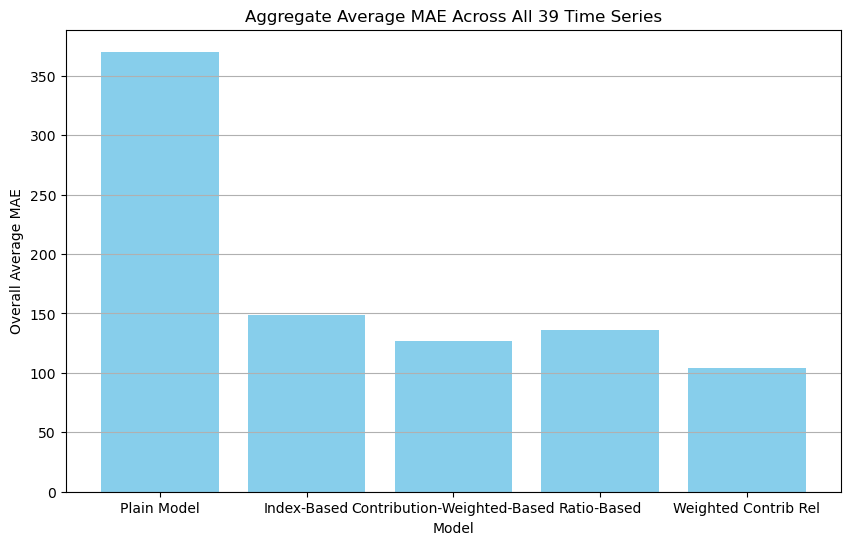

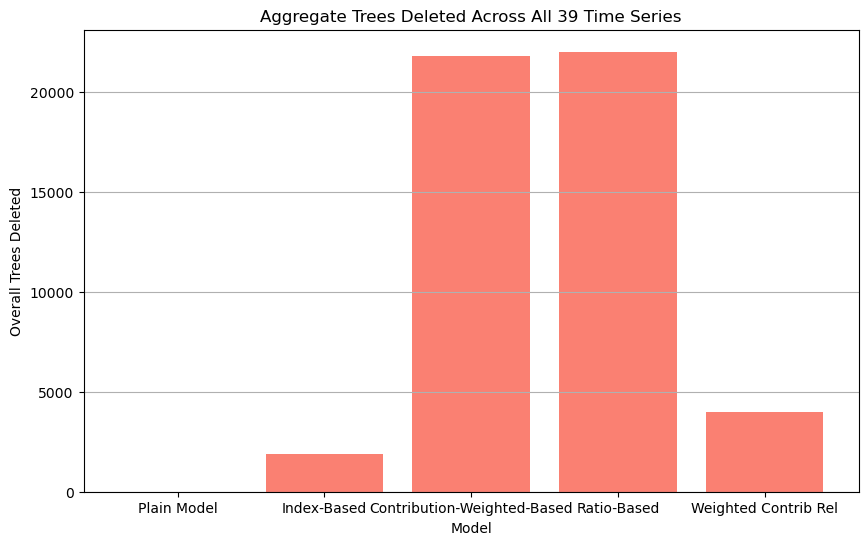

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Aggregate statistics for each model across all 39 time series.
model_names = list(per_ts_results[0]["models"].keys())
agg_results = {name: {"mae": [], "trees_deleted": []} for name in model_names}
plain_mae_all = []

for ts_stats in per_ts_results:
    plain_mae_all.append(ts_stats["avg_plain_mae"])
    for name in model_names:
        agg_results[name]["mae"].append(ts_stats["models"][name]["avg_mae"])
        agg_results[name]["trees_deleted"].append(ts_stats["models"][name]["total_trees_deleted"])

# Compute overall aggregates.
overall_results = []
for name in model_names:
    overall_avg_mae = np.mean(agg_results[name]["mae"])
    overall_trees_deleted = np.sum(agg_results[name]["trees_deleted"])
    overall_results.append({
        "Model": name,
        "Overall Average MAE": overall_avg_mae,
        "Overall Trees Deleted": overall_trees_deleted
    })
plain_overall_avg_mae = np.mean(plain_mae_all)
overall_results.insert(0, {
    "Model": "Plain Model",
    "Overall Average MAE": plain_overall_avg_mae,
    "Overall Trees Deleted": 0
})

overall_results_df = pd.DataFrame(overall_results)
print("Aggregate Statistics Across All 39 Time Series:")
print(overall_results_df)

# Plot overall average MAE per model.
plt.figure(figsize=(10, 6))
models_list = overall_results_df["Model"].tolist()
avg_mae_list = overall_results_df["Overall Average MAE"].tolist()
plt.bar(models_list, avg_mae_list, color='skyblue')
plt.xlabel("Model")
plt.ylabel("Overall Average MAE")
plt.title("Aggregate Average MAE Across All 39 Time Series")
plt.grid(axis='y')
plt.show()

# Plot overall trees deleted per model.
plt.figure(figsize=(10, 6))
trees_deleted_list = overall_results_df["Overall Trees Deleted"].tolist()
plt.bar(models_list, trees_deleted_list, color='salmon')
plt.xlabel("Model")
plt.ylabel("Overall Trees Deleted")
plt.title("Aggregate Trees Deleted Across All 39 Time Series")
plt.grid(axis='y')
plt.show()


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

import sys
import os

# Determine the directory of the current script.
current_dir = os.path.dirname(os.path.abspath("meter_data_processing.ipynb"))
# Get the parent directory (the project root which contains both 'src' and 'notebooks').
parent_dir = os.path.dirname(current_dir)
# Insert the parent directory at the beginning of sys.path if it's not already there.
if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)

print("Updated sys.path:", sys.path)  # For debugging; remove when done.

from src.elasticGBDT import ElasticGBDT

# Your code can now use ElasticGBDT


# ============================================================================
# 1. Base Model Training
# ============================================================================

# Assume X_train_full, y_train_full, X_test_all, y_test_all are available.
# Also, n_seed is the number of seed samples from the test series to use in training.
# For example:
#   n_seed = max(1, int(test_training_ratio * len(X_test_all)))
# (In your earlier preprocessing you computed n_seed)

# Combine training series and seed from test series for base model training
X_train = np.vstack((X_train_full, X_test_all[:n_seed]))
y_train = np.hstack((y_train_full, y_test_all[:n_seed]))

# Train the base Gradient Boosting model.
# Feel free to adjust parameters (n_estimators, learning_rate, max_depth, etc.)
base_model = GradientBoostingRegressor(
    n_estimators=40,
    learning_rate=0.1,
    max_depth=5,
    random_state=42
)
base_model.fit(X_train, y_train)

Updated sys.path: ['c:\\Users\\stros\\Documents\\Mycroft\\Incremental-Learning-MycroftMinds', 'c:\\Users\\stros\\AppData\\Local\\anaconda3\\python312.zip', 'c:\\Users\\stros\\AppData\\Local\\anaconda3\\DLLs', 'c:\\Users\\stros\\AppData\\Local\\anaconda3\\Lib', 'c:\\Users\\stros\\AppData\\Local\\anaconda3', '', 'C:\\Users\\stros\\AppData\\Roaming\\Python\\Python312\\site-packages', 'C:\\Users\\stros\\AppData\\Roaming\\Python\\Python312\\site-packages\\win32', 'C:\\Users\\stros\\AppData\\Roaming\\Python\\Python312\\site-packages\\win32\\lib', 'C:\\Users\\stros\\AppData\\Roaming\\Python\\Python312\\site-packages\\Pythonwin', 'c:\\Users\\stros\\AppData\\Local\\anaconda3\\Lib\\site-packages', 'c:\\Users\\stros\\AppData\\Local\\anaconda3\\Lib\\site-packages\\win32', 'c:\\Users\\stros\\AppData\\Local\\anaconda3\\Lib\\site-packages\\win32\\lib', 'c:\\Users\\stros\\AppData\\Local\\anaconda3\\Lib\\site-packages\\Pythonwin']


GradientBoostingRegressor(max_depth=5, n_estimators=40, random_state=42)